In [60]:
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

In [61]:
treatments = {'ctrl2_basal': ['TAH5505A1'], 
              'glib_basal': ['TAH5505A10'], 
              'glib_A1 low': ['TAH5505A11'], 
              'glib_A1 high': ['TAH5505A12'], 
              'cbie_basal': ['TAH5505A13'], 
              'cbie_A1 low': ['TAH5505A14'], 
              'cbie_A1 high': ['TAH5505A15'], 
              'ctrl6_basal': ['TAH5505A16'], 
              'ctrl6_A1 low': ['TAH5505A17'], 
              'ctrl6_A1 high': ['TAH5505A18'], 
              'ctrl2_A1 low': ['TAH5505A2'], 
              'ctrl2_A1 high': ['TAH5505A3'], 
              'ctrl3_basal': ['TAH5505A4'], 
              'ctrl3_A1 low': ['TAH5505A5'], 
              'ctrl3_A1 high': ['TAH5505A6'], 
              'glia_basal': ['TAH5505A7'], 
              'glia_A1 low': ['TAH5505A8'], 
              'glia_A1 high': ['TAH5505A9']}

In [62]:
treatments_cell_line = {'ctrl_basal': [],
                        'ctrl_A1 low': [],
                        'ctrl_A1 high': [],
                        'vcp_basal': [],
                        'vcp_A1 low': [],
                        'vcp_A1 high': [],}


for new_cat in treatments_cell_line.keys():
    for treatment, sample_ids in treatments.items():
        s = new_cat.split("_")[0]
        t = new_cat.split("_")[1]
        if s == 'ctrl':
            if 'ctrl' in treatment and t in treatment:
                treatments_cell_line[new_cat].extend(sample_ids)
        else:
            if 'ctrl' not in treatment and t in treatment:
                treatments_cell_line[new_cat].extend(sample_ids)
                

In [63]:
table_of_pairs = pd.read_csv("/idiap/temp/group/genomics/AstroBF_fastq/RN22346/230106_A01366_0335_BHJJHNDSX5/3UTR_analysis_grouped/table_of_pairs.csv", index_col=0)

In [64]:
PUD_columns = [col for col in table_of_pairs.columns if col.startswith('PUD_') and "TAH" not in col and "significance" not in col]
table_PUD = table_of_pairs[PUD_columns]
table_PUD.columns = [col.split("PUD_")[1] for col in table_PUD.columns]

In [65]:
palette_genotype = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }
palette_treatment = {'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"}

In [66]:
df_PUD = pd.melt(table_PUD)
df_PUD['genotype'] = df_PUD['variable'].apply(lambda x: x.split("_")[0])
df_PUD['treatment'] = df_PUD['variable'].apply(lambda x: "_".join(x.split("_")[1:]))

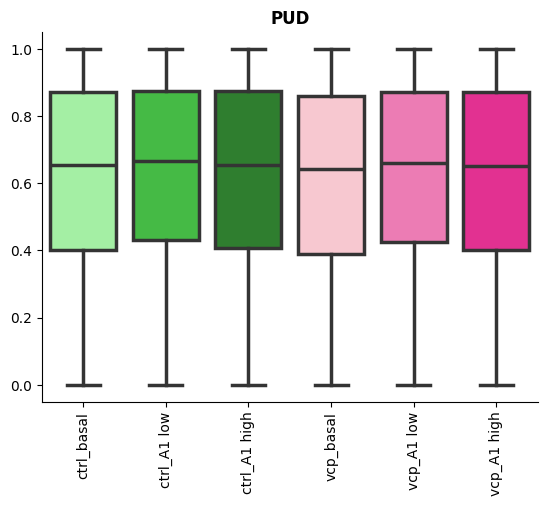

In [67]:
sns.boxplot(table_PUD, palette=palette_genotype, linewidth=2.5)
plt.xticks(rotation=90)
sns.despine()
plt.title("PUD", weight='bold');

In [68]:
# df_PUD['value'] = pd.to_numeric(df_PUD['value'], errors='coerce')

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl_basal vs. ctrl_A1 low: P=1.29e-04
ctrl_A1 low vs. ctrl_A1 high: P=1.84e-03
ctrl_A1 high vs. vcp_basal: P=1.50e-04
vcp_basal vs. vcp_A1 low: P=4.01e-09
vcp_A1 low vs. vcp_A1 high: P=8.70e-04
ctrl_basal vs. ctrl_A1 high: P=4.73e-01
ctrl_A1 low vs. vcp_basal: P=4.18e-12
ctrl_A1 high vs. vcp_A1 low: P=3.89e-02
vcp_basal vs. vcp_A1 high: P=1.15e-02
ctrl_basal vs. vcp_basal: P=2.19e-03
ctrl_A1 low vs. vcp_A1 low: P=2.89e-01
ctrl_A1 high vs. vcp_A1 high: P=2.08e-01
ctrl_basal vs. vcp_A1 low: P=5.41e-03
ctrl_A1 low vs. vcp_A1 high: P=1.20e-05
ctrl_basal vs. vcp_A1 high: P=5.90e-01


Text(0.5, 58.5815972222222, '')

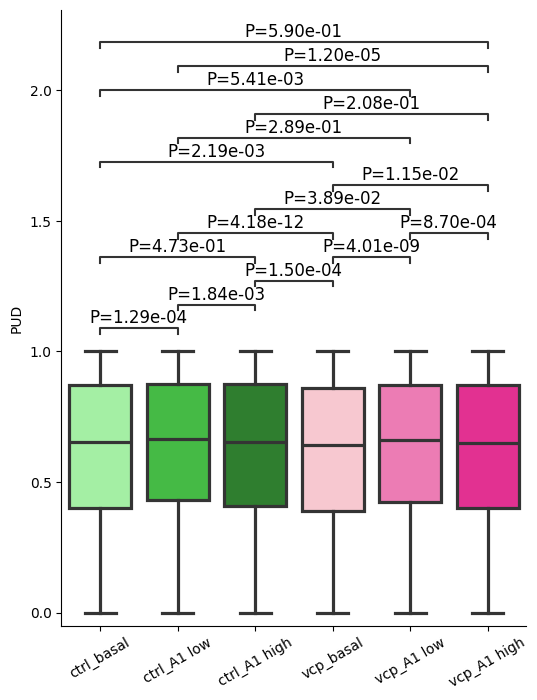

In [69]:
from melapa.helper_plot import plot_boxplot_significance
plt.figure(figsize=(6, 8))
plot_boxplot_significance(df_PUD, 
                          x='variable', 
                          y='value',
                          palette=palette_genotype, stripplot=False)

plt.ylabel("PUD")
plt.xlabel("")


In [70]:
df_PUD

,variable,value,genotype,treatment
0,ctrl_basal,0.812286,ctrl,basal
1,ctrl_basal,0.651404,ctrl,basal
2,ctrl_basal,0.948948,ctrl,basal
3,ctrl_basal,0.902406,ctrl,basal
4,ctrl_basal,0.588087,ctrl,basal
...,...,...,...,...
88813,vcp_A1 high,0.653192,vcp,A1 high
88814,vcp_A1 high,0.652314,vcp,A1 high
88815,vcp_A1 high,0.914110,vcp,A1 high
88816,vcp_A1 high,0.806846,vcp,A1 high


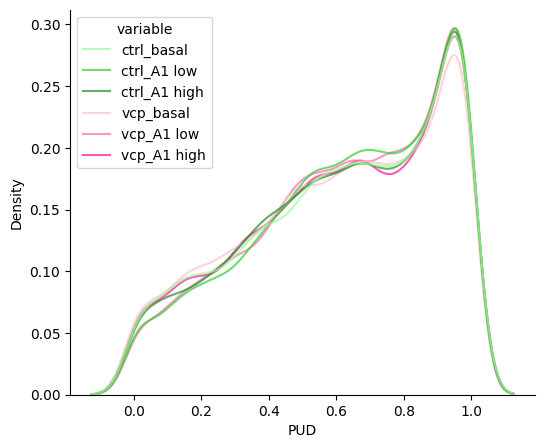

In [71]:
from melapa.helper_plot import plot_boxplot_significance
plt.figure(figsize=(6, 5))
sns.kdeplot(df_PUD, 
            x='value', 
            hue='variable',
            palette=palette_genotype, alpha=0.7, fill=False)
sns.despine()
plt.xlabel("PUD")
sns.move_legend(loc="upper left", obj=plt.gca())

Text(0.5, 0, 'PUD')

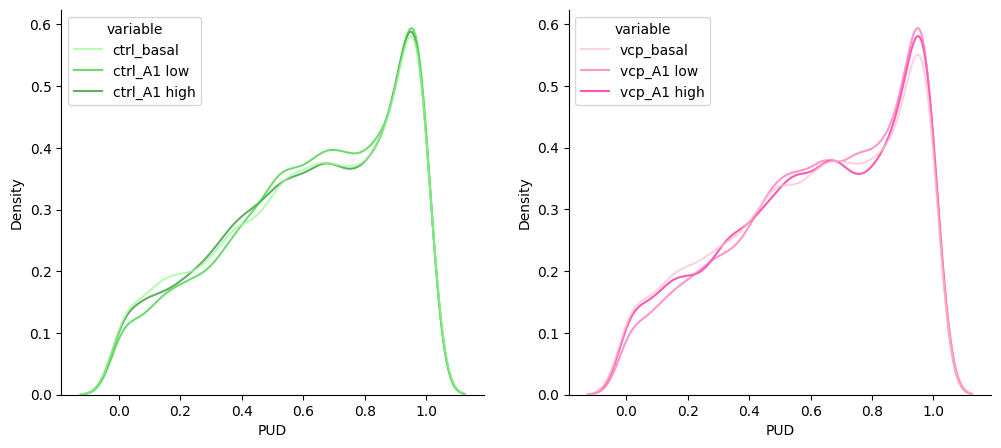

In [72]:
from melapa.helper_plot import plot_boxplot_significance
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.kdeplot(df_PUD[df_PUD['genotype'] == 'ctrl'], 
            x='value', 
            hue='variable',
            palette=palette_genotype, alpha=0.7, fill=False)
sns.despine()
sns.move_legend(loc="upper left", obj=plt.gca())
plt.xlabel("PUD")

plt.subplot(1, 2, 2)
sns.kdeplot(df_PUD[df_PUD['genotype'] == 'vcp'], 
            x='value', 
            hue='variable',
            palette=palette_genotype, alpha=0.7, fill=False)
sns.despine()
sns.move_legend(loc="upper left", obj=plt.gca())
plt.xlabel("PUD")

Text(0, 0.5, 'PUD')

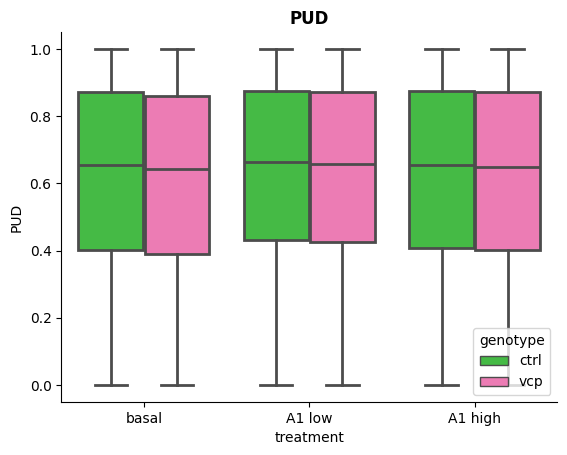

In [73]:
sns.boxplot(df_PUD, 
            x='treatment', 
            y='value', 
            hue='genotype', 
            palette={"ctrl": 'limegreen', 'vcp': 'hotpink'},
            linewidth=2)
sns.despine()
plt.title("PUD", weight='bold');
plt.ylabel("PUD")

Text(0, 0.5, 'PUD')

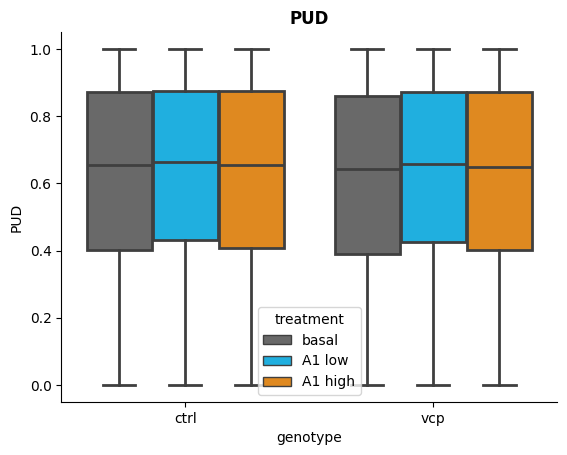

In [74]:
sns.boxplot(df_PUD, 
            x='genotype', 
            y='value', 
            hue='treatment', 
            palette=palette_treatment,
            linewidth=2)
sns.despine()
plt.title("PUD", weight='bold');
plt.ylabel("PUD")

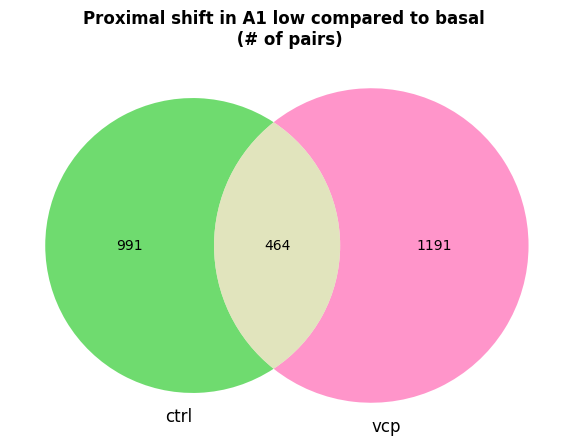

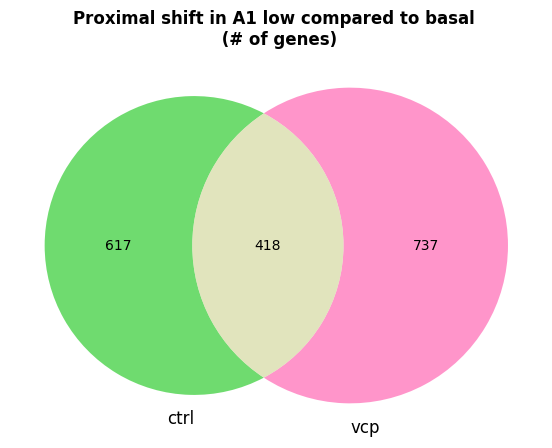

In [98]:
from matplotlib_venn import venn2


pairs_prox_shift_A1_low_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant proximal shift")]['distal_id']
pairs_prox_shift_A1_low_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 low'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 low'] == "Significant proximal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_prox_shift_A1_low_ctrl)
set_vcp = set(pairs_prox_shift_A1_low_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 low compared to basal \n (# of pairs)", weight='bold')
plt.show()


genes_prox_shift_A1_low_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant proximal shift")]['gene']
genes_prox_shift_A1_low_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 low'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 low'] == "Significant proximal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_prox_shift_A1_low_ctrl)
set_vcp = set(genes_prox_shift_A1_low_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 low compared to basal \n (# of genes)", weight='bold')
plt.show()


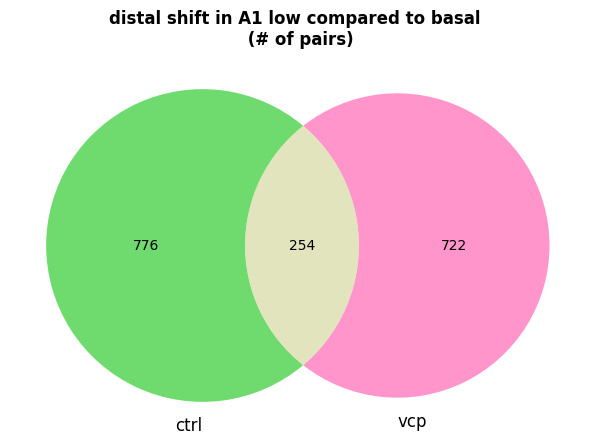

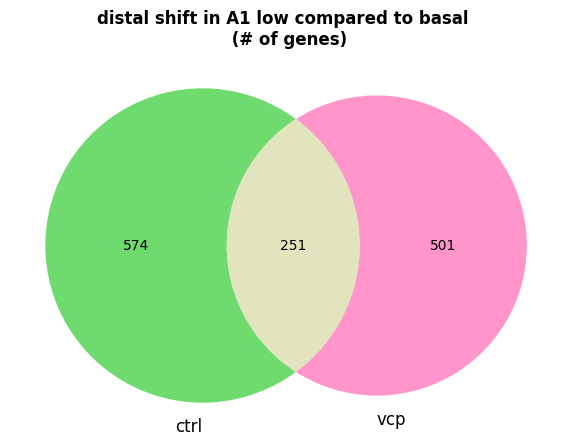

In [99]:
from matplotlib_venn import venn2


pairs_dist_shift_A1_low_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant distal shift")]['distal_id']
pairs_dist_shift_A1_low_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 low'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 low'] == "Significant distal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_dist_shift_A1_low_ctrl)
set_vcp = set(pairs_dist_shift_A1_low_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 low compared to basal \n (# of pairs)", weight='bold')
plt.show()


genes_dist_shift_A1_low_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 low'] == "Significant distal shift")]['gene']
genes_dist_shift_A1_low_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 low'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 low'] == "Significant distal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_dist_shift_A1_low_ctrl)
set_vcp = set(genes_dist_shift_A1_low_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 low compared to basal \n (# of genes)", weight='bold')
plt.show()


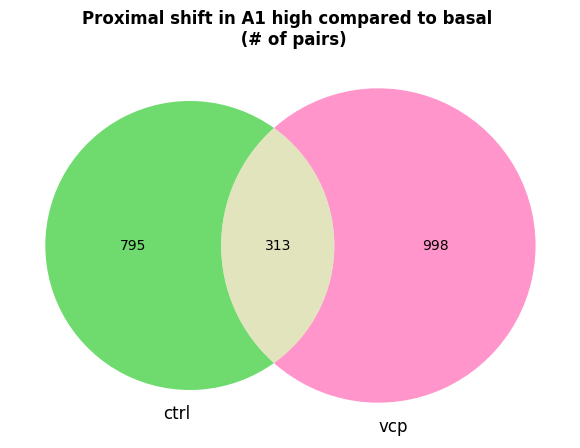

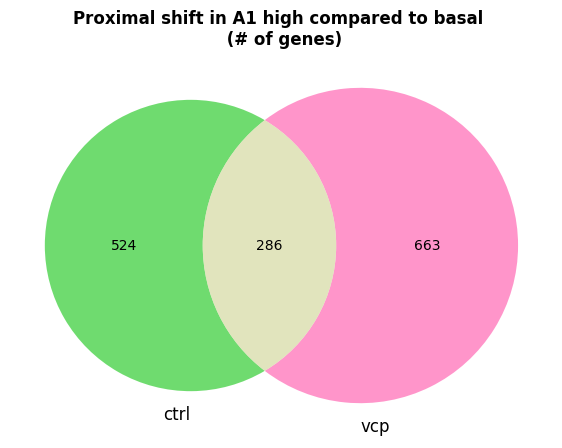

In [100]:
from matplotlib_venn import venn2


pairs_prox_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant proximal shift")]['distal_id']
pairs_prox_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 high'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 high'] == "Significant proximal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_prox_shift_A1_high_ctrl)
set_vcp = set(pairs_prox_shift_A1_high_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 high compared to basal \n (# of pairs)", weight='bold')
plt.show()


genes_prox_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant proximal shift")]['gene']
genes_prox_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 high'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 high'] == "Significant proximal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_prox_shift_A1_high_ctrl)
set_vcp = set(genes_prox_shift_A1_high_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 high compared to basal \n (# of genes)", weight='bold')
plt.show()


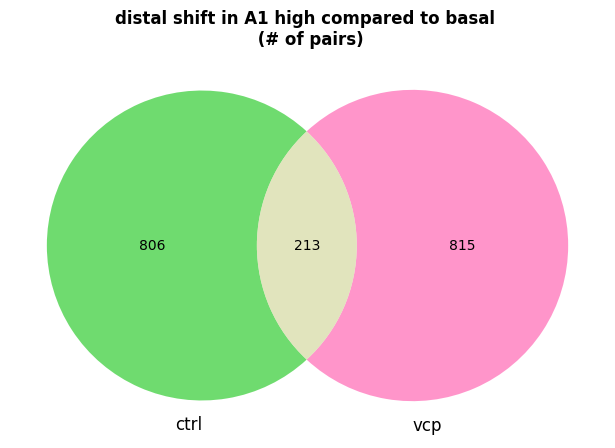

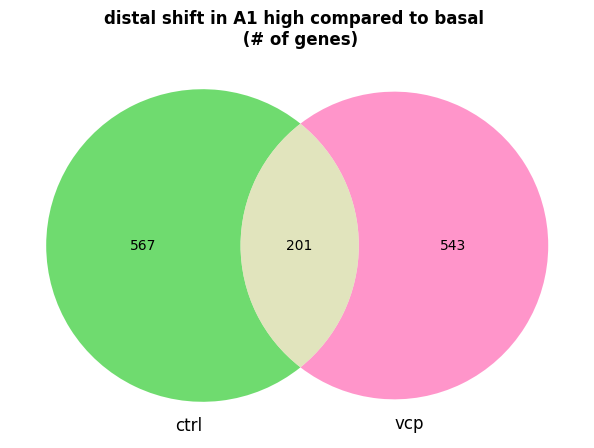

In [101]:
from matplotlib_venn import venn2


pairs_dist_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant distal shift")]['distal_id']
pairs_dist_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 high'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 high'] == "Significant distal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_dist_shift_A1_high_ctrl)
set_vcp = set(pairs_dist_shift_A1_high_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 high compared to basal \n (# of pairs)", weight='bold')
plt.show()


genes_dist_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_ctrl_A1 high'] == "Significant distal shift")]['gene']
genes_dist_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_basal_vcp_A1 high'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_basal_vcp_A1 high'] == "Significant distal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_dist_shift_A1_high_ctrl)
set_vcp = set(genes_dist_shift_A1_high_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 high compared to basal \n (# of genes)", weight='bold')
plt.show()

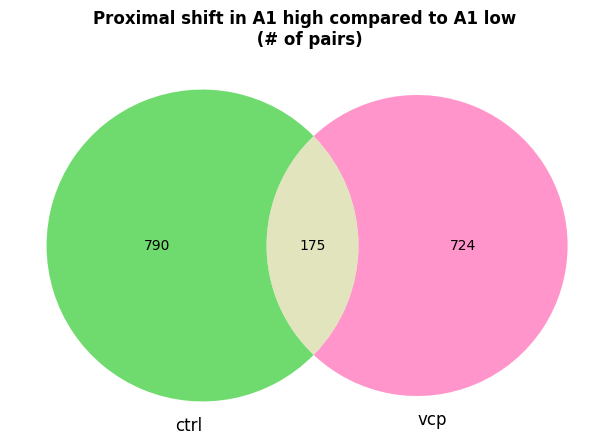

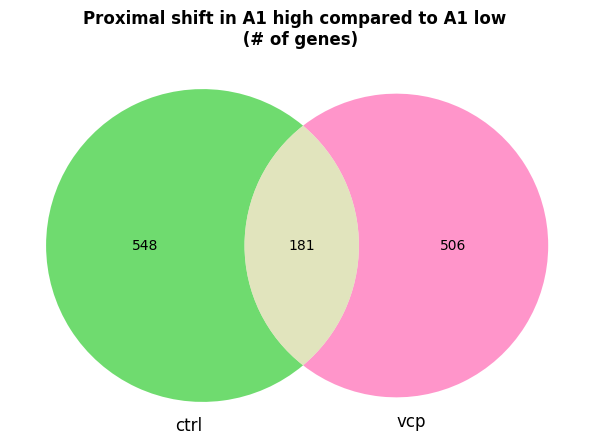

In [102]:
from matplotlib_venn import venn2


pairs_prox_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant proximal shift")]['distal_id']
pairs_prox_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant proximal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_prox_shift_A1_high_ctrl)
set_vcp = set(pairs_prox_shift_A1_high_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 high compared to A1 low \n (# of pairs)", weight='bold')
plt.show()


genes_prox_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant proximal shift")]['gene']
genes_prox_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant proximal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant proximal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_prox_shift_A1_high_ctrl)
set_vcp = set(genes_prox_shift_A1_high_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"Proximal shift in A1 high compared to A1 low \n (# of genes)", weight='bold')
plt.show()


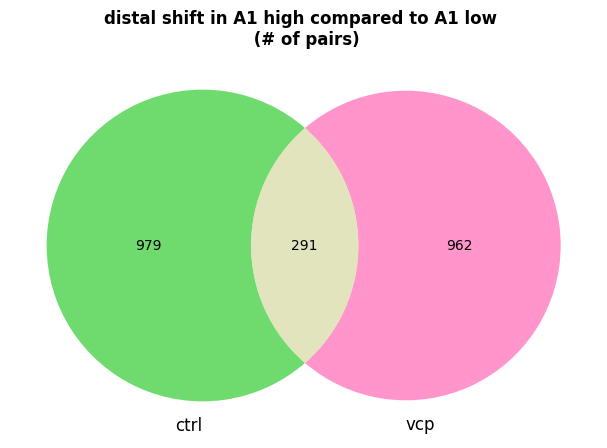

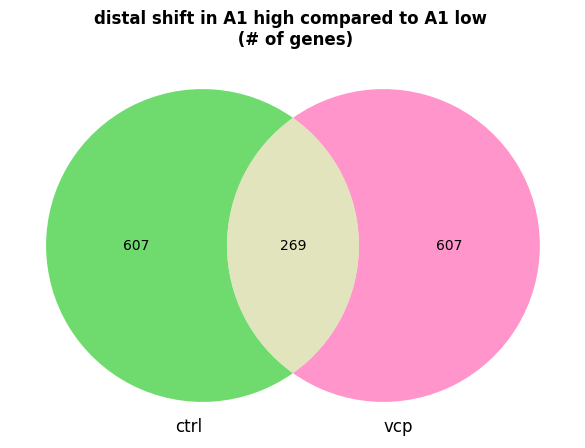

In [103]:
from matplotlib_venn import venn2


pairs_dist_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant distal shift")]['distal_id']
pairs_dist_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant distal shift")]['distal_id']

# Get sets of distal_id for each group
set_ctrl = set(pairs_dist_shift_A1_high_ctrl)
set_vcp = set(pairs_dist_shift_A1_high_vcp)

plt.figure(figsize=(10, 5))

venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 high compared to A1 low \n (# of pairs)", weight='bold')
plt.show()


genes_dist_shift_A1_high_ctrl = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_A1 low_ctrl_A1 high'] == "Significant distal shift")]['gene']
genes_dist_shift_A1_high_vcp = table_of_pairs[(table_of_pairs['PUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant distal shift") 
                                             & (table_of_pairs['RUD_significance_vcp_A1 low_vcp_A1 high'] == "Significant distal shift")]['gene']

# Get sets of distal_id for each group
set_ctrl = set(genes_dist_shift_A1_high_ctrl)
set_vcp = set(genes_dist_shift_A1_high_vcp)


plt.figure(figsize=(10, 5))
venn2([set_ctrl, set_vcp], 
    set_labels=('ctrl', 'vcp'), 
    set_colors=('limegreen', 'hotpink'), 
    alpha=0.7)
plt.title(f"distal shift in A1 high compared to A1 low \n (# of genes)", weight='bold')
plt.show()


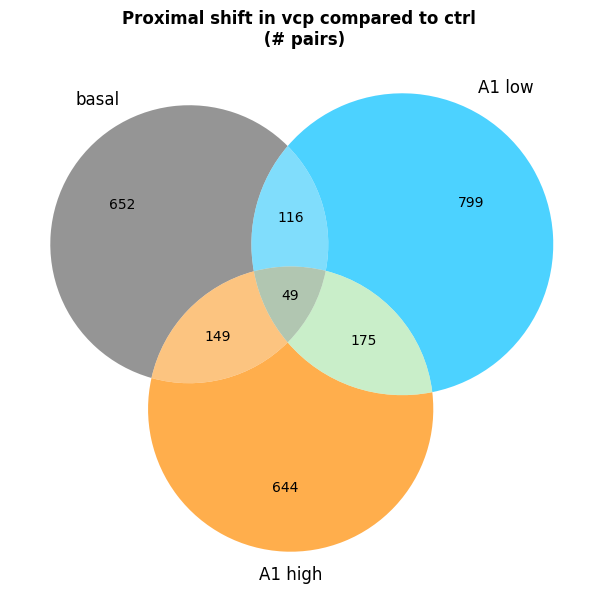

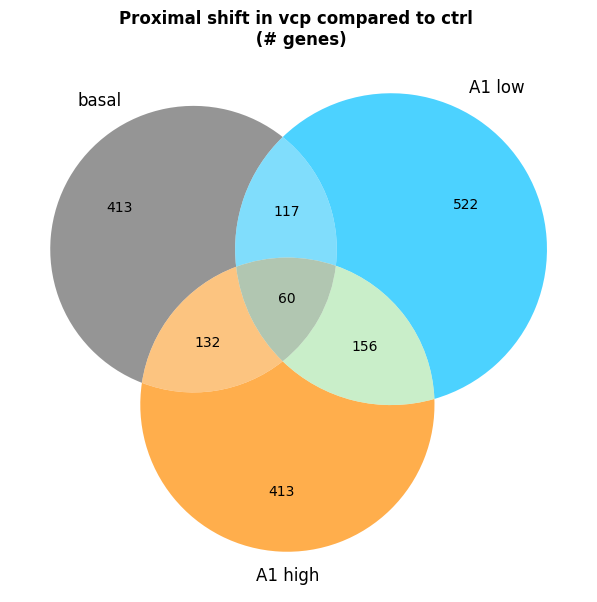

In [104]:
from matplotlib_venn import venn3


pairs_prox_shift_basal = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_vcp_basal'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_vcp_basal'] == "Significant proximal shift")]['distal_id']
pairs_prox_shift_A1_low = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant proximal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant proximal shift")]['distal_id']
pairs_prox_shift_A1_high = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant proximal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant proximal shift")]['distal_id']


set_basal = set(pairs_prox_shift_basal)
set_A1_low = set(pairs_prox_shift_A1_low)
set_A1_high = set(pairs_prox_shift_A1_high)

plt.figure(figsize=(10, 7))
venn3([set_basal, set_A1_low, set_A1_high],
    set_labels=('basal', 'A1 low', 'A1 high'),
    set_colors=('dimgray', 'deepskyblue', 'darkorange'),
    alpha=0.7)
plt.title(f"Proximal shift in vcp compared to ctrl \n (# pairs)", weight='bold')
plt.show()

from matplotlib_venn import venn3


genes_prox_shift_basal = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_vcp_basal'] == "Significant proximal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_vcp_basal'] == "Significant proximal shift")]['gene']
genes_prox_shift_A1_low = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant proximal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant proximal shift")]['gene']
genes_prox_shift_A1_high = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant proximal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant proximal shift")]['gene']


set_basal = set(genes_prox_shift_basal)
set_A1_low = set(genes_prox_shift_A1_low)
set_A1_high = set(genes_prox_shift_A1_high)

plt.figure(figsize=(10, 7))
venn3([set_basal, set_A1_low, set_A1_high],
    set_labels=('basal', 'A1 low', 'A1 high'),
    set_colors=('dimgray', 'deepskyblue', 'darkorange'),
    alpha=0.7)
plt.title(f"Proximal shift in vcp compared to ctrl \n (# genes)", weight='bold')
plt.show()



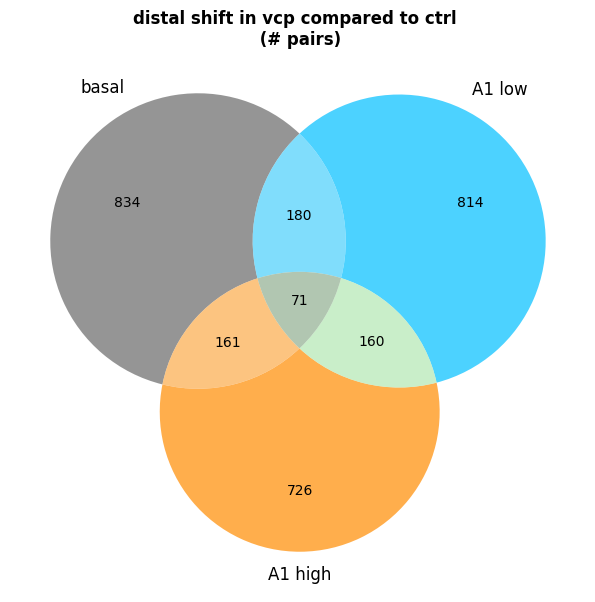

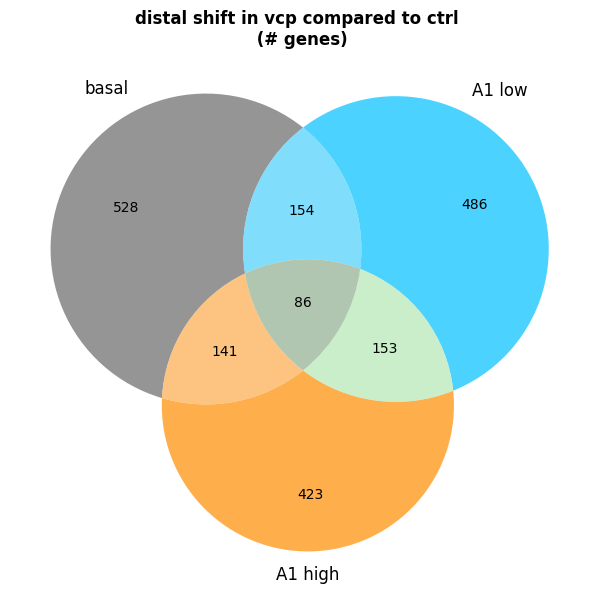

In [105]:
from matplotlib_venn import venn3


pairs_dist_shift_basal = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_vcp_basal'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_vcp_basal'] == "Significant distal shift")]['distal_id']
pairs_dist_shift_A1_low = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant distal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant distal shift")]['distal_id']
pairs_dist_shift_A1_high = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant distal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant distal shift")]['distal_id']


set_basal = set(pairs_dist_shift_basal)
set_A1_low = set(pairs_dist_shift_A1_low)
set_A1_high = set(pairs_dist_shift_A1_high)

plt.figure(figsize=(10, 7))
venn3([set_basal, set_A1_low, set_A1_high],
    set_labels=('basal', 'A1 low', 'A1 high'),
    set_colors=('dimgray', 'deepskyblue', 'darkorange'),
    alpha=0.7)
plt.title(f"distal shift in vcp compared to ctrl \n (# pairs)", weight='bold')
plt.show()

from matplotlib_venn import venn3


genes_dist_shift_basal = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_basal_vcp_basal'] == "Significant distal shift") 
                                              & (table_of_pairs['RUD_significance_ctrl_basal_vcp_basal'] == "Significant distal shift")]['gene']
genes_dist_shift_A1_low = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant distal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 low_vcp_A1 low'] == "Significant distal shift")]['gene']
genes_dist_shift_A1_high = table_of_pairs[(table_of_pairs['PUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant distal shift")
                                             & (table_of_pairs['RUD_significance_ctrl_A1 high_vcp_A1 high'] == "Significant distal shift")]['gene']


set_basal = set(genes_dist_shift_basal)
set_A1_low = set(genes_dist_shift_A1_low)
set_A1_high = set(genes_dist_shift_A1_high)

plt.figure(figsize=(10, 7))
venn3([set_basal, set_A1_low, set_A1_high],
    set_labels=('basal', 'A1 low', 'A1 high'),
    set_colors=('dimgray', 'deepskyblue', 'darkorange'),
    alpha=0.7)
plt.title(f"distal shift in vcp compared to ctrl \n (# genes)", weight='bold')
plt.show()


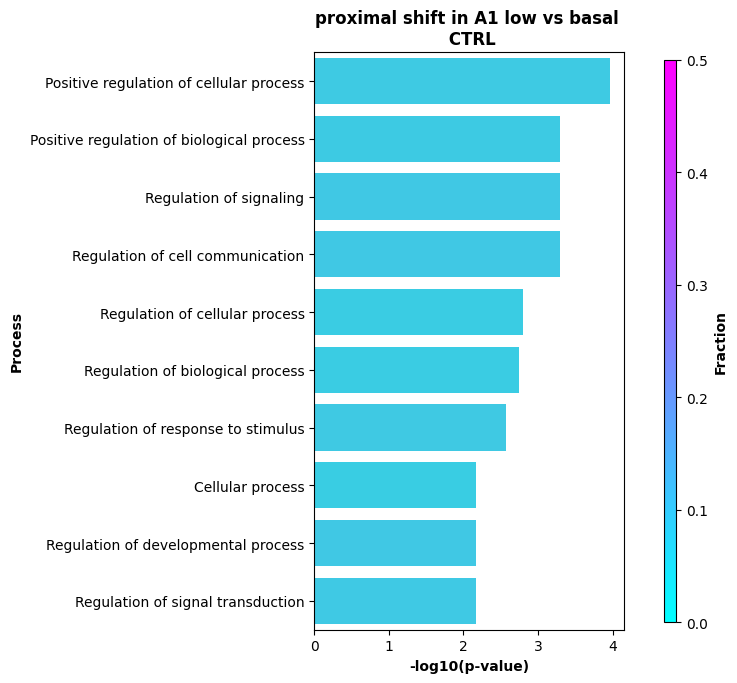

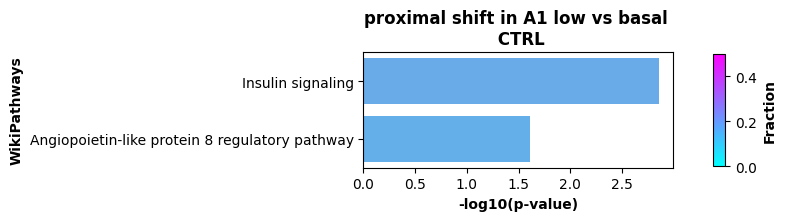

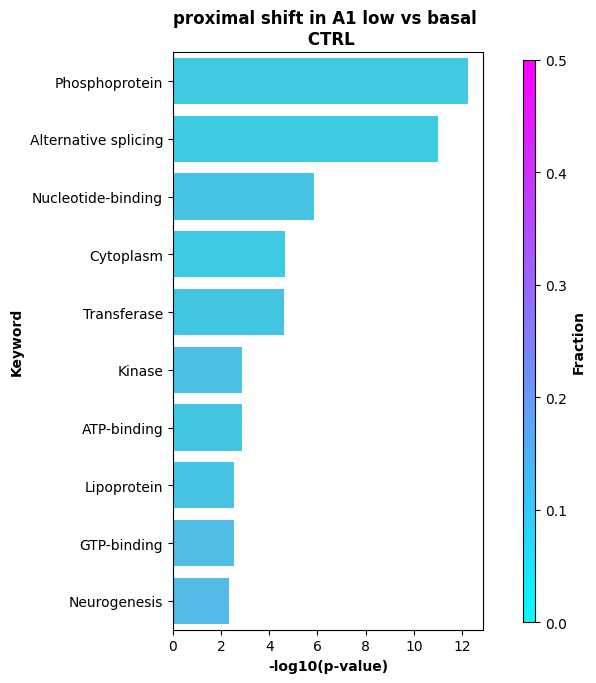

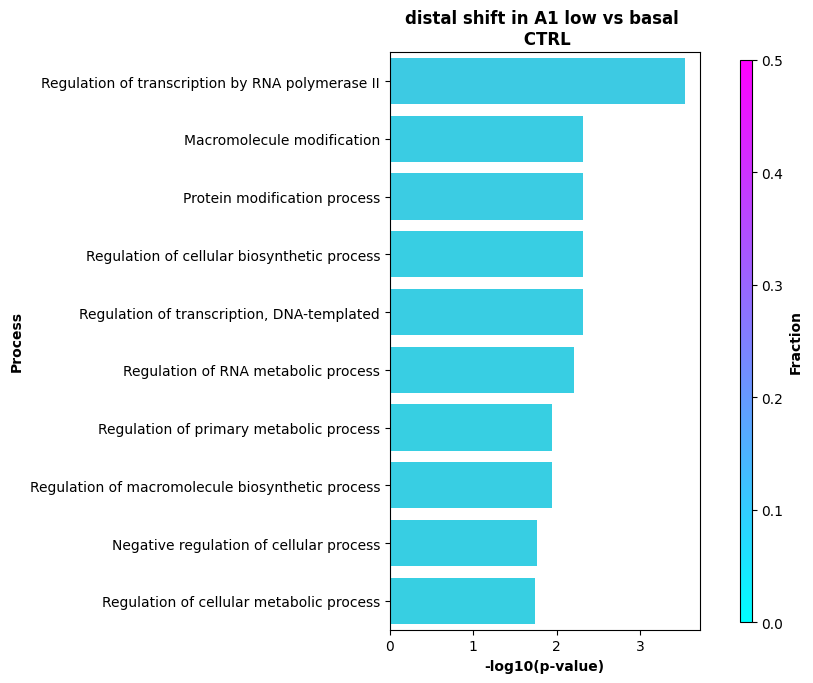

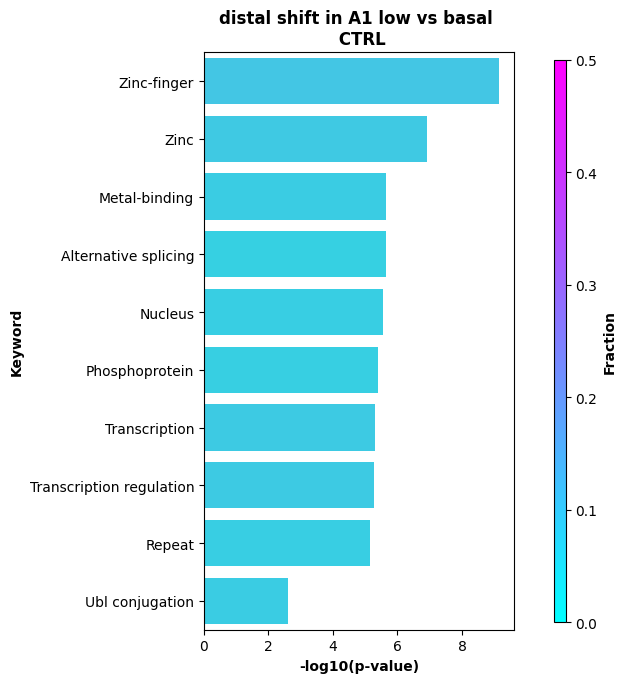

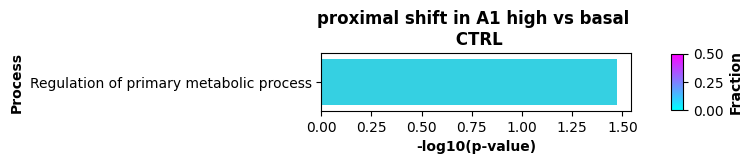

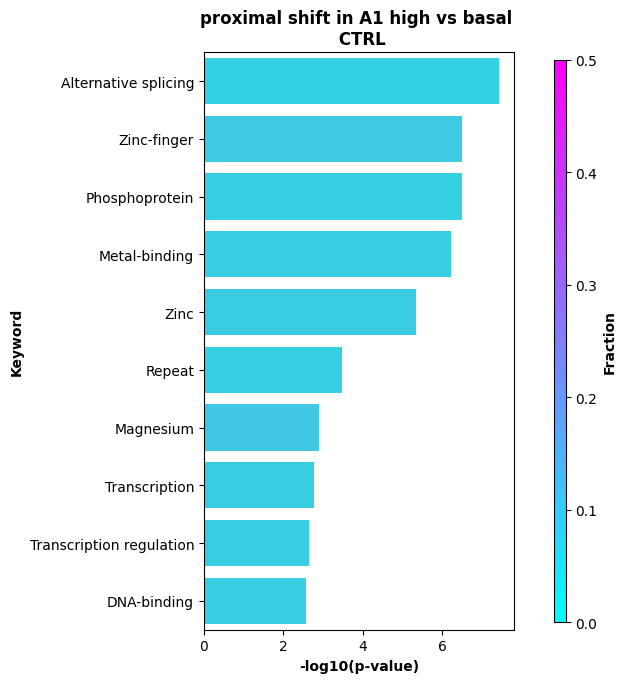

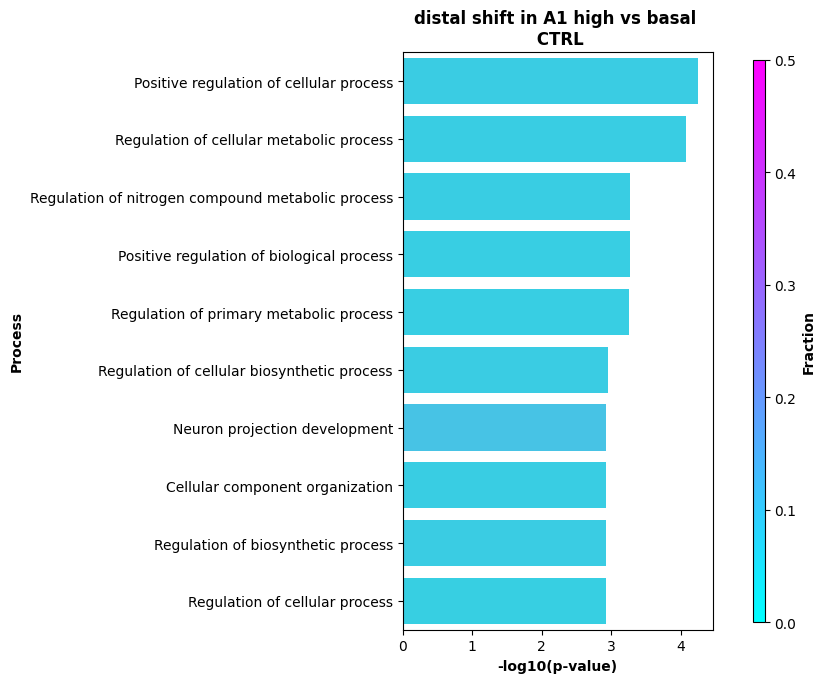

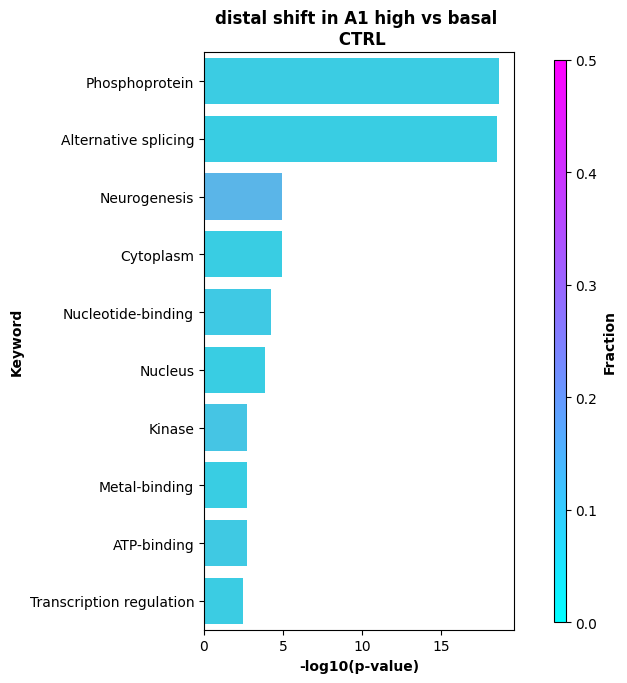

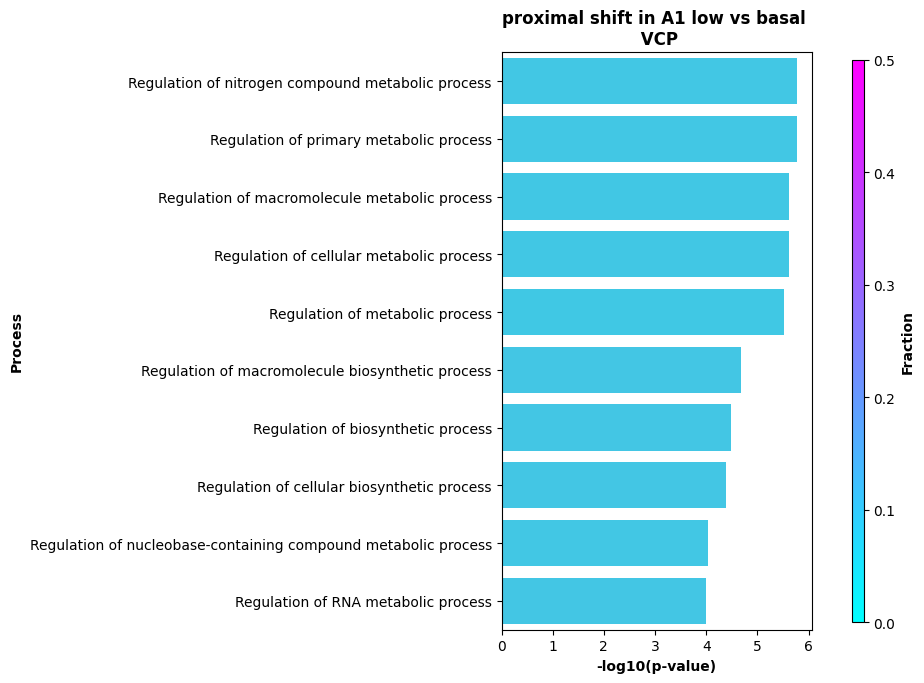

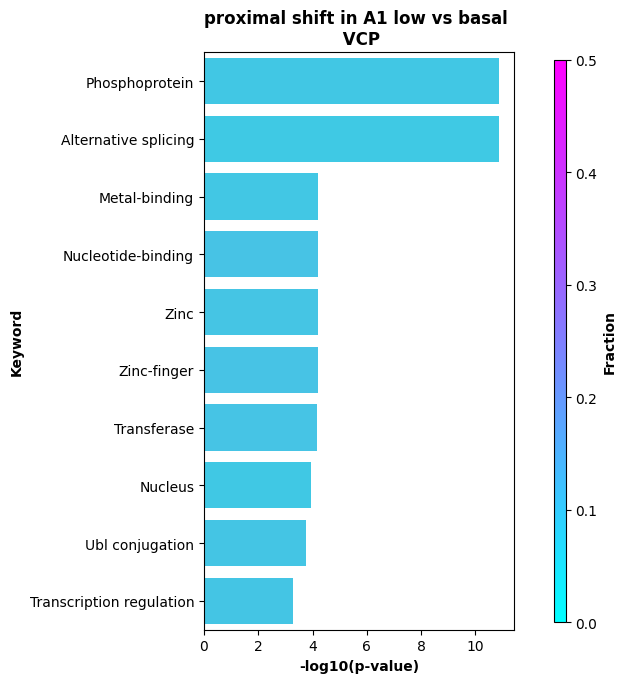

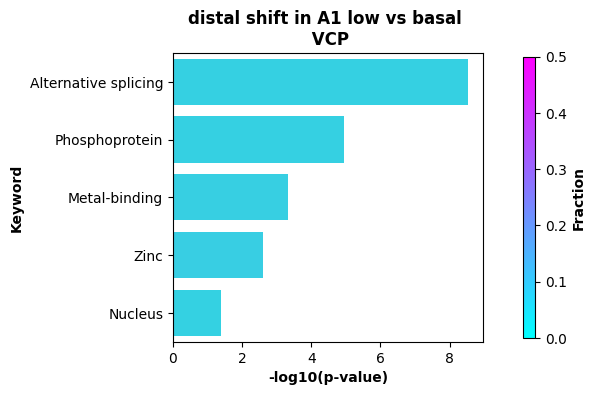

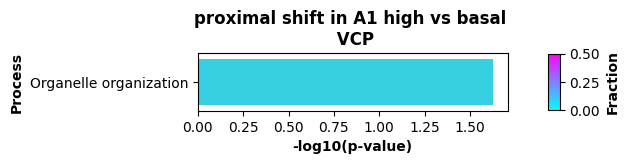

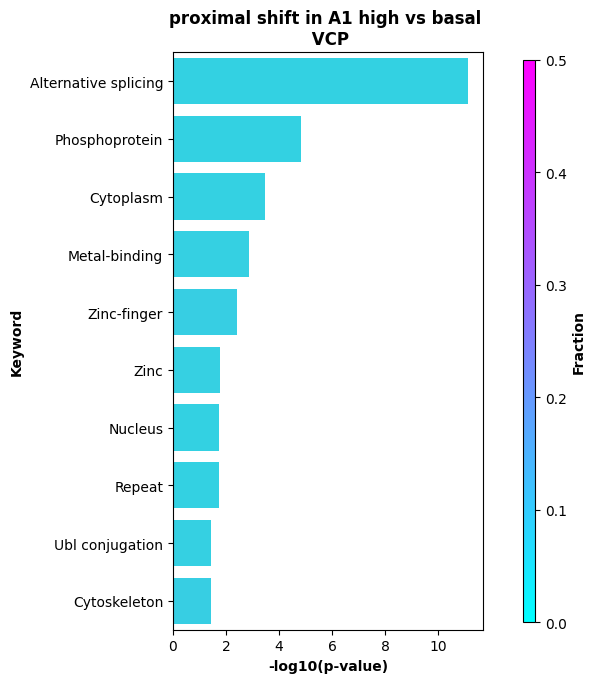

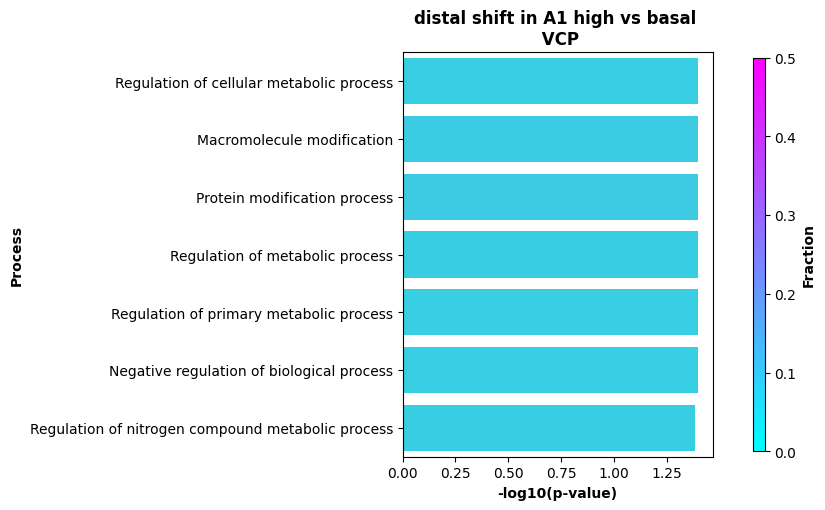

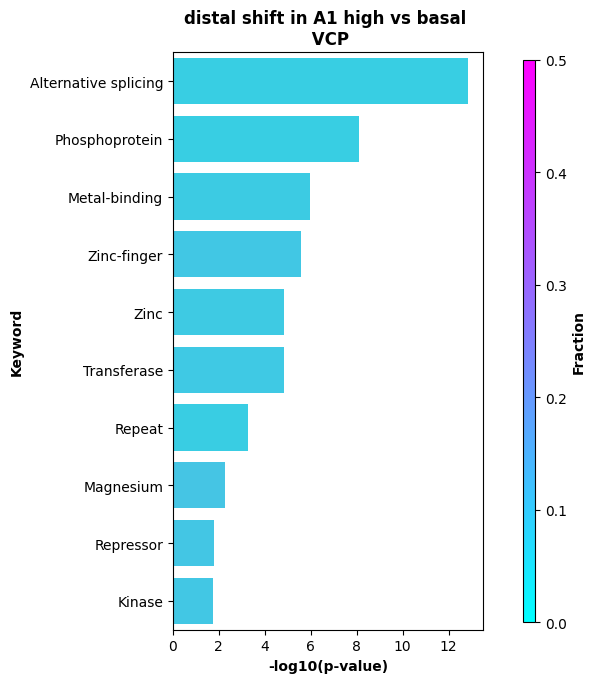

In [ ]:
from matplotlib import cm
import stringdb
from pybpanalysis.stringdb_helper import stringdb_barplot_all_class, stringdb_dotplot_one_class, stringdb_barplot_one_class, get_BP_heatmaps

for gene_list, event in zip([genes_prox_shift_A1_low_ctrl, 
                             genes_dist_shift_A1_low_ctrl, 
                             genes_prox_shift_A1_high_ctrl, 
                             genes_dist_shift_A1_high_ctrl,
                             genes_prox_shift_A1_low_vcp,
                             genes_dist_shift_A1_low_vcp,
                             genes_prox_shift_A1_high_vcp,
                             genes_dist_shift_A1_high_vcp], 
                            [f"proximal shift in A1 low vs basal \n CTRL",
                             f"distal shift in A1 low vs basal \n CTRL",
                             f"proximal shift in A1 high vs basal \n CTRL",
                             f"distal shift in A1 high vs basal \n CTRL",
                             f"proximal shift in A1 low vs basal \n VCP",
                             f"distal shift in A1 low vs basal \n VCP",
                             f"proximal shift in A1 high vs basal \n VCP",
                             f"distal shift in A1 high vs basal \n VCP"]):
    string_ids = stringdb.get_string_ids(gene_list)
    enrichment_df = stringdb.get_enrichment(string_ids.queryItem)
    enrichment_df = enrichment_df[enrichment_df['number_of_genes'] >= 5]
    if 'Process' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='Process', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'KEGG' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='KEGG', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'WikiPathways' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='WikiPathways', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'Keyword' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='Keyword', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)


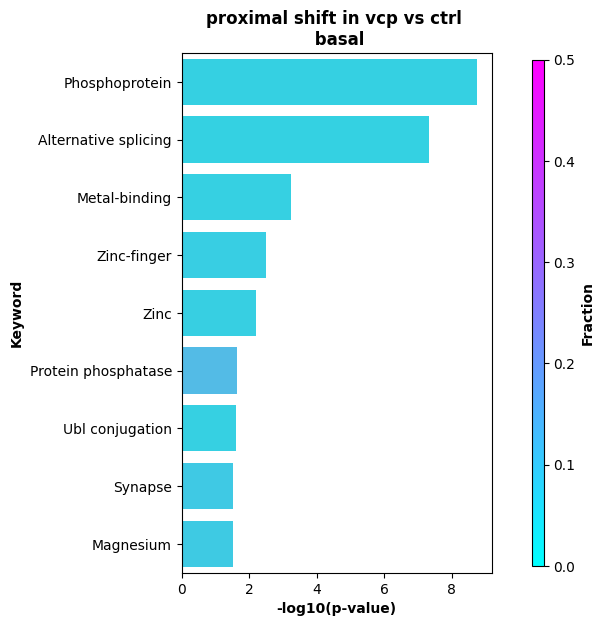

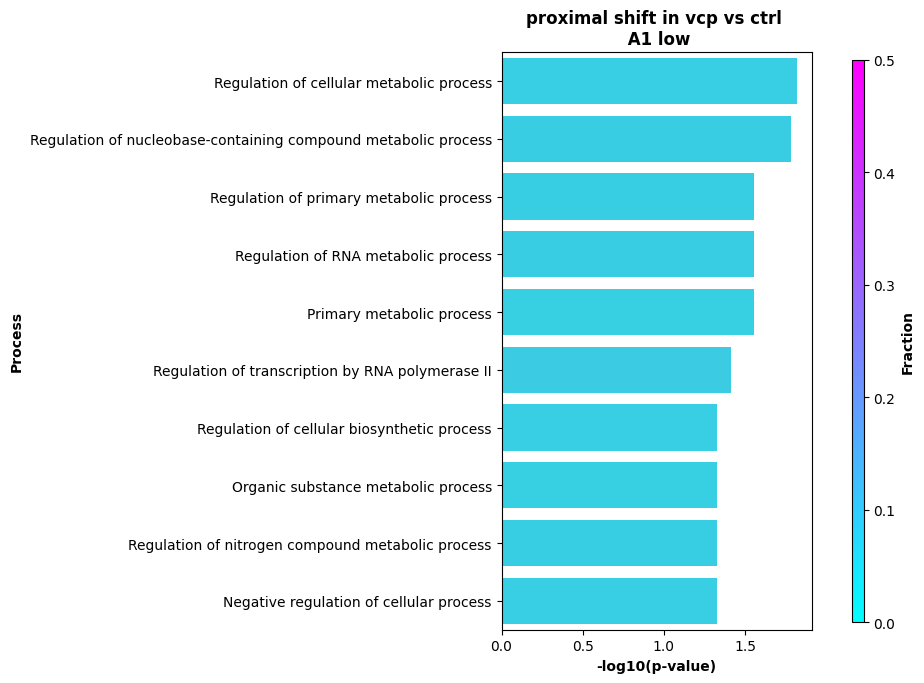

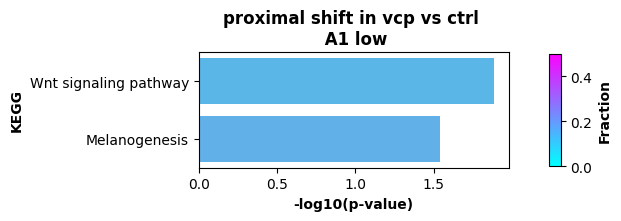

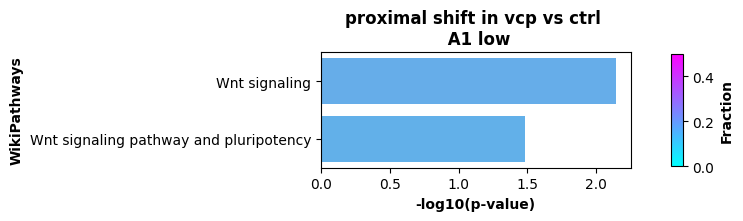

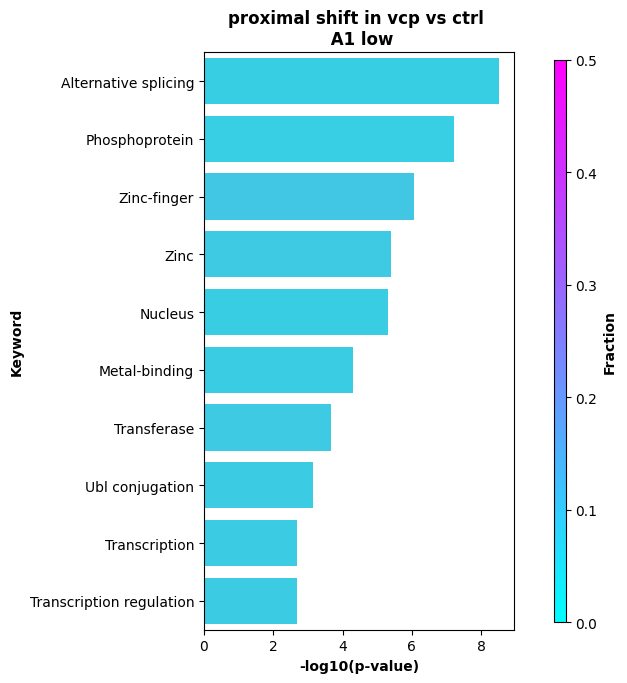

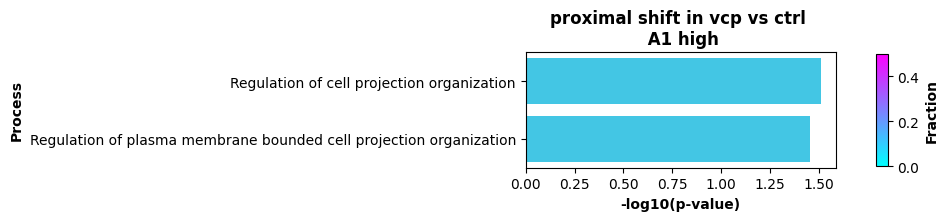

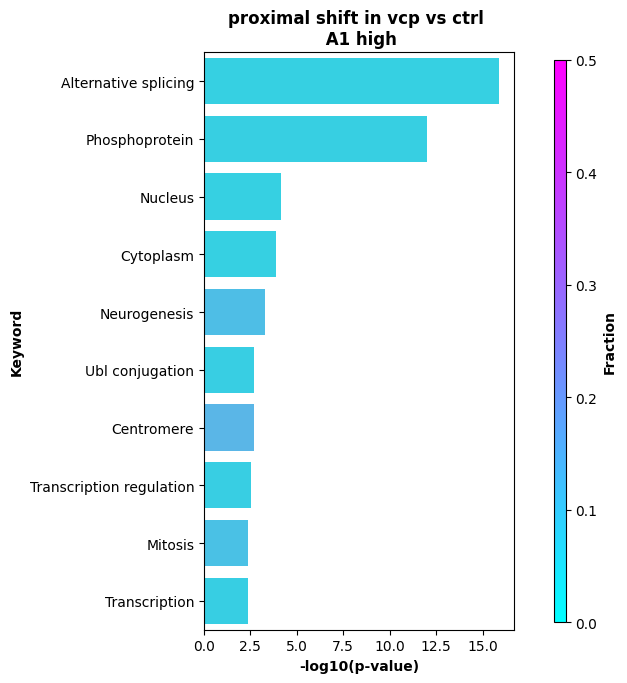

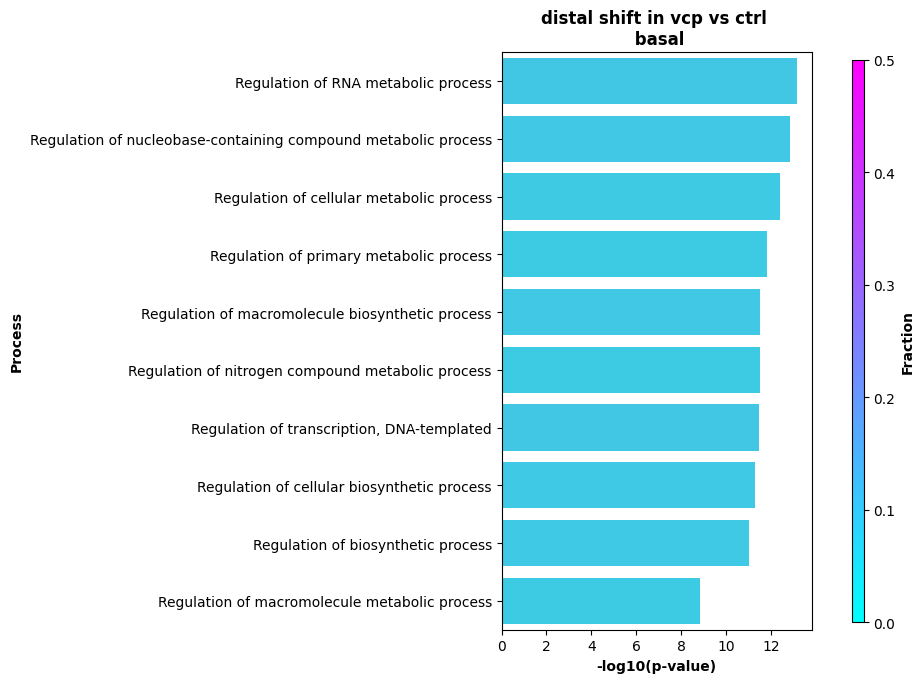

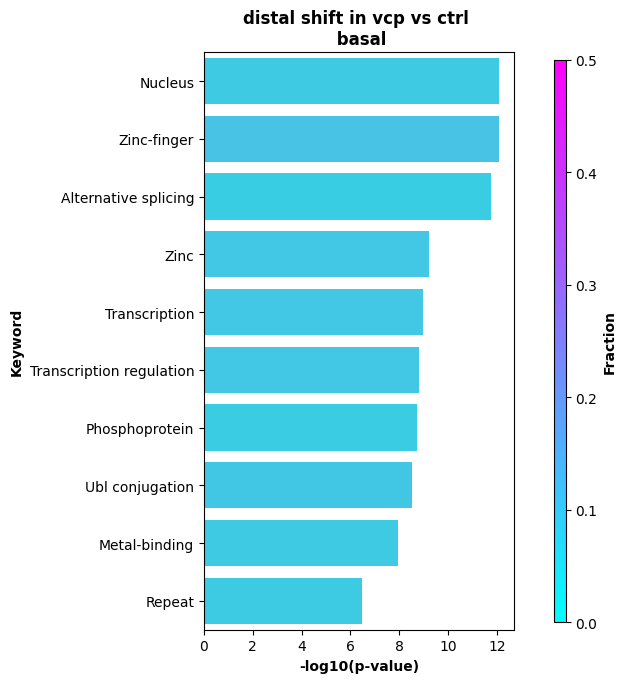

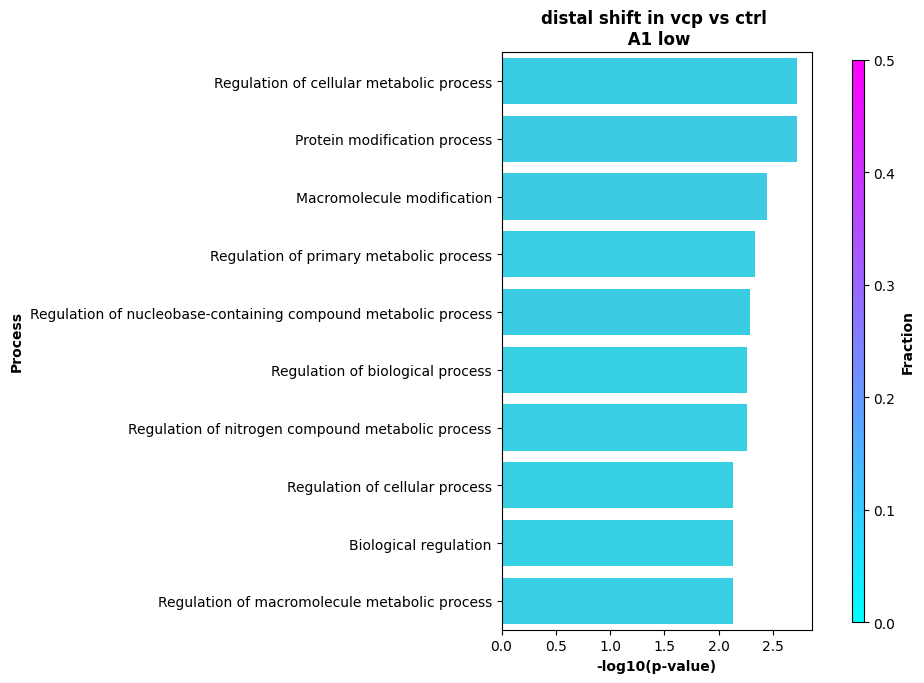

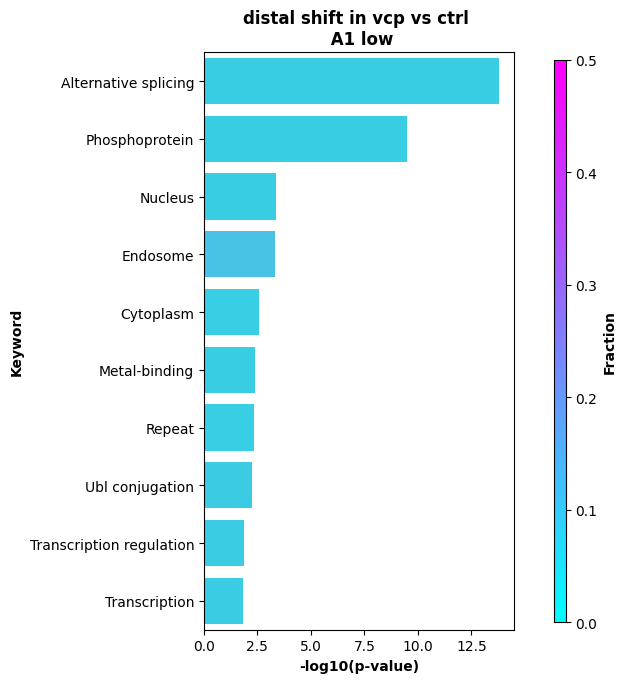

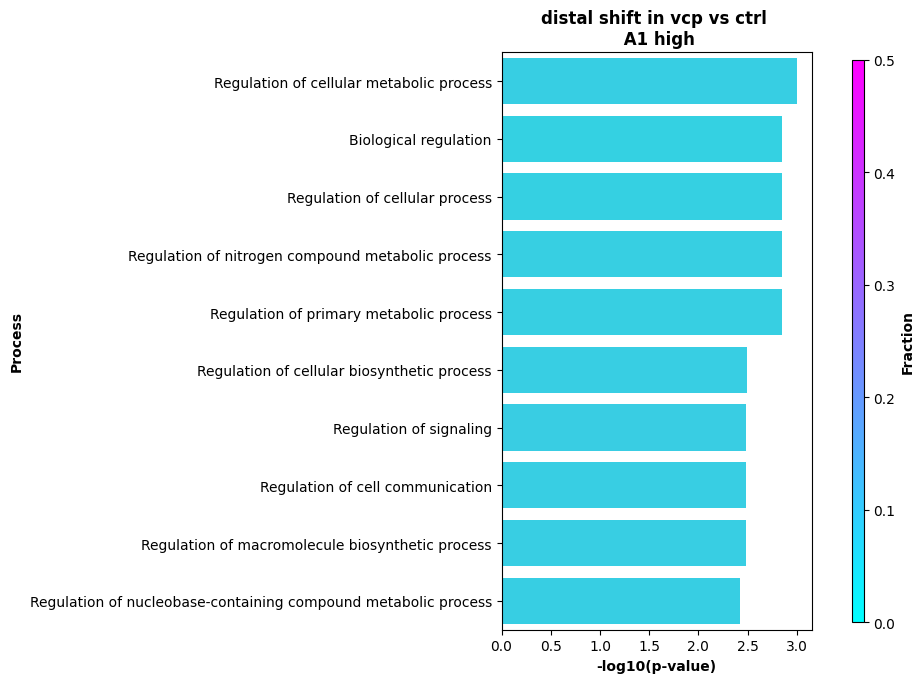

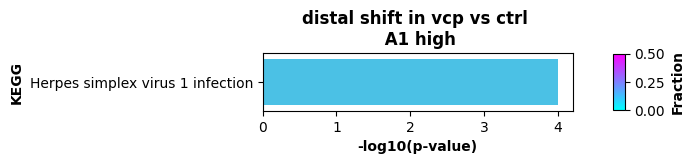

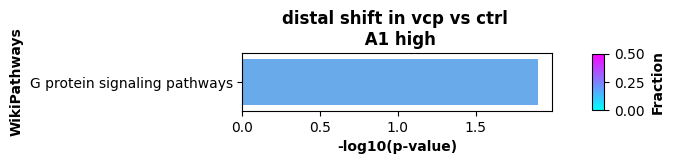

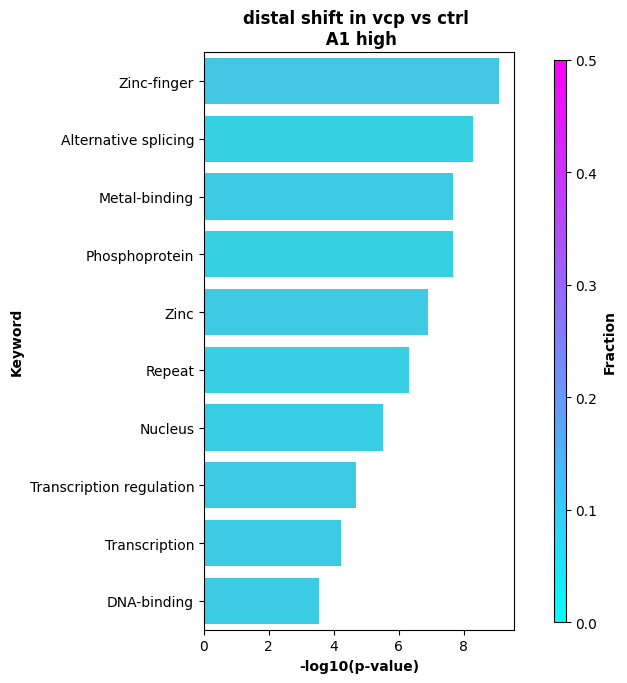

In [110]:
for gene_list, event in zip([genes_prox_shift_basal,
                             genes_prox_shift_A1_low,
                             genes_prox_shift_A1_high,
                             genes_dist_shift_basal,
                             genes_dist_shift_A1_low,
                             genes_dist_shift_A1_high], 
                            [f"proximal shift in vcp vs ctrl \n basal",
                             f"proximal shift in vcp vs ctrl \n A1 low",
                             f"proximal shift in vcp vs ctrl \n A1 high",
                             f"distal shift in vcp vs ctrl \n basal",
                             f"distal shift in vcp vs ctrl \n A1 low",
                             f"distal shift in vcp vs ctrl \n A1 high"]):
    string_ids = stringdb.get_string_ids(gene_list)
    enrichment_df = stringdb.get_enrichment(string_ids.queryItem)
    enrichment_df = enrichment_df[enrichment_df['number_of_genes'] >= 5]
    if 'Process' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='Process', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'KEGG' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='KEGG', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'WikiPathways' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='WikiPathways', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
    if 'Keyword' in enrichment_df.value_counts('category').index:
        stringdb_barplot_one_class(df=enrichment_df, nb_top=10, clas='Keyword', cmap=cm.cool, title=event, vmin=0, vmax=0.5, frac_x=False)
